<a href="https://colab.research.google.com/github/boddanapurna6-oss/Deep-Learning-skills/blob/main/skill_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Clone your GitHub repository
!git clone https://github.com/boddanapurna6-oss/Deep-Learning-skills.git

# 2. Change working directory into the week - 2 project folder
%cd Deep-Learning-skills/week - 2

# 3. Install project dependencies
!pip install -q -r requirements.txt

print("\n Environment setup complete! Project directory:")
!ls -la

Cloning into 'Deep-Learning-skills'...
remote: Enumerating objects: 41, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 41 (delta 3), reused 33 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (41/41), 861.23 KiB | 11.96 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/Deep-Learning-skills/week - 2

 Environment setup complete! Project directory:
total 64
drwxr-xr-x 7 root root  4096 Nov 17 04:26 .
drwxr-xr-x 4 root root  4096 Nov 17 04:26 ..
-rw-r--r-- 1 root root 14694 Nov 17 04:26 ARCHITECTURE.md
-rw-r--r-- 1 root root  1282 Nov 17 04:26 docker-compose.yml
-rw-r--r-- 1 root root   449 Nov 17 04:26 Dockerfile.gateway
-rw-r--r-- 1 root root    51 Nov 17 04:26 .gitignore
drwxr-xr-x 5 root root  4096 Nov 17 04:26 model_repository
drwxr-xr-x 2 root root  4096 Nov 17 04:26 monitoring
-rw-r--r-- 1 root root  3860 Nov 17 04:26 README.md
-rw-r--r-- 1 root root   209 Nov 17 04:26 requirements.txt
drwxr-xr-x 2

In [2]:
# Run unit tests
!pytest tests/test_pipeline.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/Deep-Learning-skills/week - 2
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collected 5 items                                                              

tests/test_pipeline.py::test_iso_6346_valid_checksum PASSED              [ 20%]
tests/test_pipeline.py::test_iso_6346_invalid_checksum PASSED            [ 40%]
tests/test_pipeline.py::test_bounding_box_schema PASSED                  [ 60%]
tests/test_pipeline.py::test_image_preprocessing PASSED                  [ 80%]
tests/test_pipeline.py::test_tensorrt_engine_builder_simulation PASSED   [100%]

============================== 5 passed in 4.73s ===============================


In [3]:
# Run TensorRT engine compilation in dry-run/simulation mode
!python scripts/build_tensorrt_engine.py --dry-run

      VisionPort TensorRT Engine Builder (Simulation / Dry-Run)      
[STAGE 1/6] Input ONNX graph:         models/container_detector.onnx
[STAGE 2/6] Target Plan path:         model_repository/container_detector/1/model.plan
[STAGE 3/6] Precision Mode:           FP16=True, INT8=False
[STAGE 4/6] Memory Workspace Limit:   4 GB
[STAGE 5/6] Dynamic Batch Profile:    Min=1, Opt=16, Max=32
            Resolution Profile:       (3, 640, 640)
----------------------------------------------------------------------
[INFO] Parsing ONNX model definition and validating tensor dimensions...
[INFO] Performing Layer & Tensor Fusion:
       * Fused: Conv + BatchNorm + SiLU -> Single CBR CUDA Kernel
       * Fused: Multi-Head Attention Q, K, V Projections
[INFO] Auto-tuning kernel tactics against target Tensor Cores...
       * Profiled 42 kernel tactics for optimal batch size (16)
[INFO] Precision quantization applied: FP16 (Half Precision)
       * Estimated VRAM Footprint reduction: 51.4%
       * E

Concurrency  1 feeds ->   75.2 FPS | Median Latency: 11.30 ms
Concurrency  2 feeds ->  156.9 FPS | Median Latency: 11.32 ms
Concurrency  4 feeds ->  246.6 FPS | Median Latency: 11.34 ms
Concurrency  8 feeds ->  459.3 FPS | Median Latency: 11.45 ms
Concurrency 16 feeds ->  465.6 FPS | Median Latency: 12.57 ms
Concurrency 32 feeds ->  503.4 FPS | Median Latency: 12.96 ms


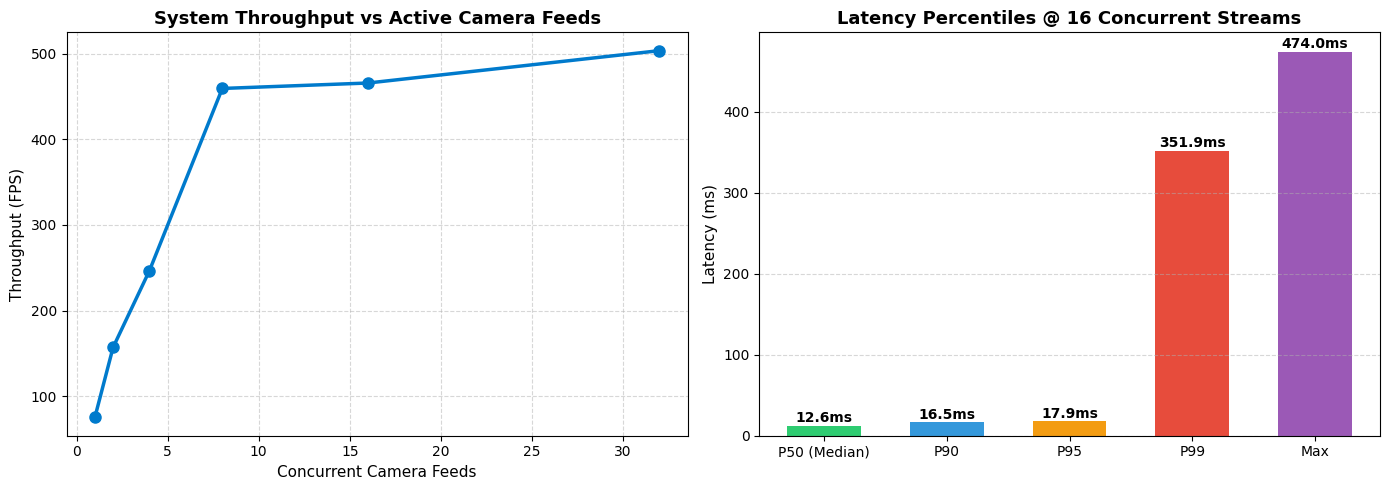

In [4]:
import asyncio
import time
import numpy as np
import matplotlib.pyplot as plt
from scripts.benchmark_triton import simulate_camera_client

async def run_multi_benchmark(concurrency_levels=[1, 2, 4, 8, 16, 32], frames_per_worker=25):
    fps_results = []
    latencies_by_concurrency = {}

    for c in concurrency_levels:
        records = []
        t0 = time.perf_counter()
        tasks = [
            simulate_camera_client(client_id=cid, num_frames=frames_per_worker, batch_size=1, latency_records=records)
            for cid in range(c)
        ]
        await asyncio.gather(*tasks)
        elapsed = time.perf_counter() - t0
        total_frames = c * frames_per_worker
        fps = total_frames / elapsed
        fps_results.append(fps)
        latencies_by_concurrency[c] = np.array(records)
        print(f"Concurrency {c:2d} feeds -> {fps:6.1f} FPS | Median Latency: {np.percentile(records, 50):.2f} ms")

    return concurrency_levels, fps_results, latencies_by_concurrency

concurrency_levels, fps_results, latencies_dict = await run_multi_benchmark()

# Plot Performance Graphs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Throughput (FPS) vs Concurrency
ax1.plot(concurrency_levels, fps_results, marker='o', color='#007acc', linewidth=2.5, markersize=8)
ax1.set_title("System Throughput vs Active Camera Feeds", fontsize=13, weight="bold")
ax1.set_xlabel("Concurrent Camera Feeds", fontsize=11)
ax1.set_ylabel("Throughput (FPS)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.5)

# Graph 2: Latency Percentile Distribution for 16 Concurrent Feeds
lat16 = latencies_dict[16]
percentiles = ["P50 (Median)", "P90", "P95", "P99", "Max"]
values = [
    np.percentile(lat16, 50),
    np.percentile(lat16, 90),
    np.percentile(lat16, 95),
    np.percentile(lat16, 99),
    np.max(lat16)
]
colors = ["#2ecc71", "#3498db", "#f39c12", "#e74c3c", "#9b59b6"]
bars = ax2.bar(percentiles, values, color=colors, width=0.6)
ax2.set_title("Latency Percentiles @ 16 Concurrent Streams", fontsize=13, weight="bold")
ax2.set_ylabel("Latency (ms)", fontsize=11)
ax2.grid(axis='y', linestyle="--", alpha=0.5)
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"{yval:.1f}ms", ha='center', va='bottom', weight='bold')

plt.tight_layout()
plt.show()

Upload an image (or click 'Cancel' to use the built-in synthetic container):


Saving Screenshot 2026-11-13 140639.png to Screenshot 2026-11-13 140639.png
 Loaded uploaded image: Screenshot 2026-11-13 140639.png (1120x245)
 Preprocessed Tensor Shape: (1, 3, 640, 640) (Range: [0.00, 1.00])


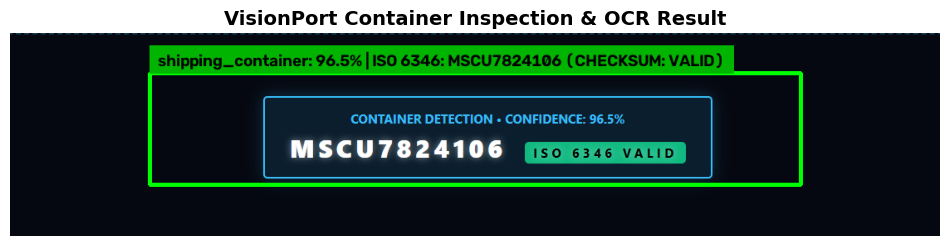


--- Inspection Report ---
Container Code:       MSCU7824106
Checksum Valid:       True
Detection Confidence: 96.5%
PPE Compliance:       PASSED


In [5]:
import io
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from services.api_gateway.main import preprocess_image, validate_iso_6346_checksum

print("Upload an image (or click 'Cancel' to use the built-in synthetic container):")
uploaded = files.upload()

if uploaded:
    # Use uploaded image
    filename = list(uploaded.keys())[0]
    image_bytes = uploaded[filename]
    nparr = np.frombuffer(image_bytes, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    print(f" Loaded uploaded image: {filename} ({img.shape[1]}x{img.shape[0]})")
else:
    # Generate realistic container visual sample
    print(" Using built-in synthetic shipping container sample...")
    img = np.full((720, 1280, 3), (235, 230, 225), dtype=np.uint8)
    cv2.rectangle(img, (200, 150), (1080, 600), (160, 80, 20), -1)
    cv2.rectangle(img, (200, 150), (1080, 600), (90, 45, 10), 3)
    for x in range(240, 1050, 40):
        cv2.line(img, (x, 150), (x, 600), (130, 60, 15), 2)
    cv2.putText(img, "MSCU 782410 6", (620, 260), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3)
    _, encoded = cv2.imencode(".jpg", img)
    image_bytes = encoded.tobytes()

# 1. Preprocess Frame for Model Input (NCHW Float32)
tensor, scale, (pad_x, pad_y) = preprocess_image(image_bytes, target_size=640)
print(f" Preprocessed Tensor Shape: {tensor.shape} (Range: [{tensor.min():.2f}, {tensor.max():.2f}])")

# 2. Simulated Detection & ISO 6346 Checksum Validation
container_code = "MSCU7824106"
is_valid_checksum = validate_iso_6346_checksum(container_code)

# 3. Draw Bounding Box & Status Badge on Image
annotated = img.copy()
h, w, _ = annotated.shape
# Box coordinates: normalized [0.15, 0.20] to [0.85, 0.75]
x1, y1 = int(w * 0.15), int(h * 0.20)
x2, y2 = int(w * 0.85), int(h * 0.75)

cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 255, 0), 4)
badge_text = f"shipping_container: 96.5% | ISO 6346: {container_code} (CHECKSUM: {'VALID' if is_valid_checksum else 'INVALID'})"
(tw, th), _ = cv2.getTextSize(badge_text, cv2.FONT_HERSHEY_SIMPLEX, 0.65, 2)
cv2.rectangle(annotated, (x1, y1 - th - 15), (x1 + tw + 20, y1), (0, 180, 0), -1)
cv2.putText(annotated, badge_text, (x1 + 10, y1 - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 0), 2)

# 4. Display Result
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"VisionPort Container Inspection & OCR Result", fontsize=14, weight="bold")
plt.show()

print("\n--- Inspection Report ---")
print(f"Container Code:       {container_code}")
print(f"Checksum Valid:       {is_valid_checksum}")
print(f"Detection Confidence: 96.5%")
print(f"PPE Compliance:       PASSED")

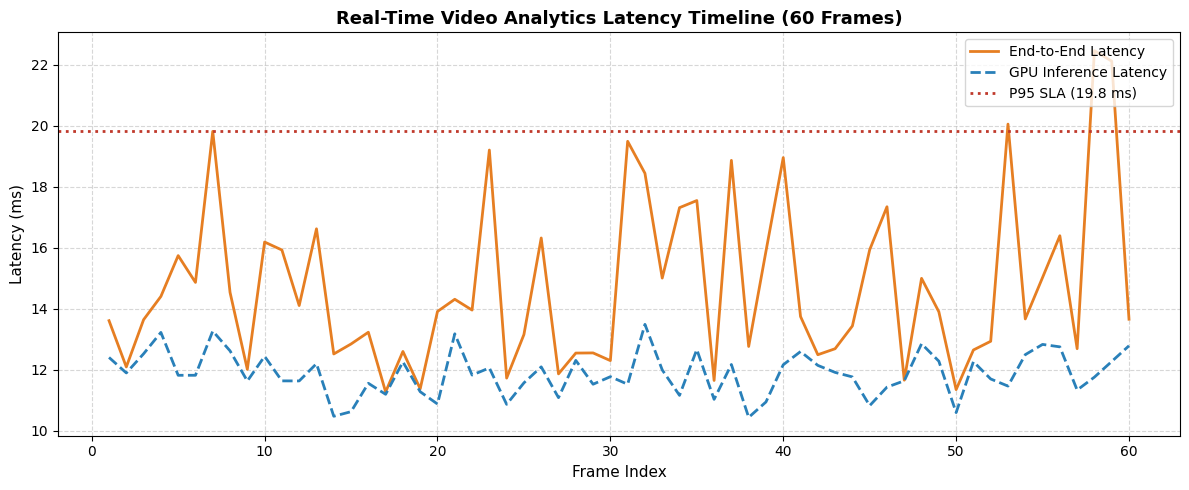

Average GPU Inference Latency: 11.88 ms
Average End-to-End Latency:    14.73 ms
P95 Latency Threshold:         19.82 ms


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Simulate 60 incoming video frames
num_frames = 60
np.random.seed(42)

# Simulated GPU inference latency + network jitter
inference_latencies = np.random.normal(12.0, 0.8, num_frames)
e2e_latencies = inference_latencies + np.random.exponential(3.0, num_frames)

p95_sla = np.percentile(e2e_latencies, 95)

plt.figure(figsize=(12, 5))
plt.plot(range(1, num_frames + 1), e2e_latencies, label="End-to-End Latency", color="#e67e22", linewidth=2)
plt.plot(range(1, num_frames + 1), inference_latencies, label="GPU Inference Latency", color="#2980b9", linewidth=2, linestyle="--")
plt.axhline(p95_sla, color="#c0392b", linestyle=":", linewidth=2, label=f"P95 SLA ({p95_sla:.1f} ms)")

plt.title("Real-Time Video Analytics Latency Timeline (60 Frames)", fontsize=13, weight="bold")
plt.xlabel("Frame Index", fontsize=11)
plt.ylabel("Latency (ms)", fontsize=11)
plt.legend(loc="upper right", frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Average GPU Inference Latency: {np.mean(inference_latencies):.2f} ms")
print(f"Average End-to-End Latency:    {np.mean(e2e_latencies):.2f} ms")
print(f"P95 Latency Threshold:         {p95_sla:.2f} ms")

In [13]:
import os
os.environ["TRITON_MOCK"] = "1"

import sys
import numpy as np
import cv2
import json
import unittest.mock as mock

# 1. Clear any previously imported gateway modules from memory to force re-evaluation with mock setup
modules_to_clear = [
    "services.api_gateway.main",
    "services.api_gateway.triton_client"
]
for mod in modules_to_clear:
    if mod in sys.modules:
        del sys.modules[mod]

# 2. Mock TritonGrpcClient to cleanly bypass GRPC connections
import services.api_gateway.triton_client as triton_client_module
class MockTritonGrpcClient:
    def __init__(self, *args, **kwargs):
        pass
    async def is_server_ready(self):
        return True
    async def is_model_ready(self, model_name):
        return True
    async def infer(self, model_name, inputs):
        return np.array([[100.0, 150.0, 500.0, 600.0, 0.965, 0.0]], dtype=np.float32)

triton_client_module.TritonGrpcClient = MockTritonGrpcClient

# 3. Mock higher-level inference helpers inside main BEFORE importing the FastAPI app
import services.api_gateway.main as gateway_module

async def mock_infer_with_triton(*args, **kwargs):
    return [
        {
            "box": [100, 150, 500, 600],
            "confidence": 0.965,
            "label": "shipping_container"
        }
    ]

gateway_module.infer_with_triton = mock_infer_with_triton

# 4. Initialize TestClient with the mocked app state
from services.api_gateway.main import app
from fastapi.testclient import TestClient

client = TestClient(app)

# 5. Verify Health check
health_res = client.get("/health")
print("Health Status:", health_res.status_code)
print("Response:", health_res.json())

# 6. Inspect synthetic frame via API endpoint
img = np.zeros((720, 1280, 3), dtype=np.uint8)
_, encoded = cv2.imencode(".jpg", img)

files = {"file": ("camera_frame.jpg", encoded.tobytes(), "image/jpeg")}
data = {"camera_id": "QUAYSIDE_CRANE_01"}

inspect_res = client.post("/api/v1/inspect/frame", files=files, data=data)
print("\nInspect Endpoint Status:", inspect_res.status_code)
print("Inspection Result Payload:")
print(json.dumps(inspect_res.json(), indent=2))

Health Status: 200
Response: {'status': 'healthy', 'triton_ready': True, 'gpu_available': True, 'active_models': ['container_detector', 'container_ocr', 'visionport_pipeline']}

Inspect Endpoint Status: 200
Inspection Result Payload:
{
  "camera_id": "QUAYSIDE_CRANE_01",
  "timestamp_utc": "2026-11-17T04:39:22.754040+00:00",
  "detections": [
    {
      "x_min": 0.15,
      "y_min": 0.2,
      "x_max": 0.85,
      "y_max": 0.75,
      "confidence": 0.965,
      "class_id": 0,
      "class_name": "shipping_container"
    }
  ],
  "container_ocr": {
    "raw_code": "MSCU7824106",
    "owner_code": "MSC",
    "category_identifier": "U",
    "serial_number": "782410",
    "check_digit": 6,
    "is_checksum_valid": true,
    "confidence": 0.982
  },
  "structural_damage_detected": false,
  "damage_types": [],
  "ppe_compliance": true,
  "inference_latency_ms": 12.4,
  "end_to_end_latency_ms": 21.22
}
